### Cell 1: Load

Read `train.csv` and `test.csv` produced by `01_prepare_data.ipynb`, and confirm the shapes match that notebook's split (31,454 train rows / 12,116 test rows, from 400/100 students).

In [2]:
import pandas as pd

train_df = pd.read_csv("../data/processed/train.csv")
test_df = pd.read_csv("../data/processed/test.csv")

print("train:", train_df.shape)
print("test:", test_df.shape)

assert train_df.shape[0] == 31454, f"expected 31454 train rows, got {train_df.shape[0]}"
assert test_df.shape[0] == 12116, f"expected 12116 test rows, got {test_df.shape[0]}"
print("shapes match notebook 1's split")

train: (31454, 9)
test: (12116, 9)
shapes match notebook 1's split


### Cell 2: Prepare the columns for pyBKT

pyBKT's default column names (`pyBKT.models.Model.DEFAULTS_BKT`) are `user_id`, `skill_name`, `correct`, `order_id`. `user_id` and `correct` already match; `skill_name` and `order_id` need to be derived:

- `skill_name` = `part`, cast to string, so pyBKT treats it as a categorical label rather than a number.
- `order_id` = a running counter over the rows as already sorted by `user_id` then `timestamp` in notebook 1. We can't use `timestamp` directly — pyBKT sorts by `order_id` internally (`data_helper.py`), and bundle questions share a timestamp, which would make the ordering within a bundle ambiguous.

In [3]:
def add_bkt_columns(df):
    df = df.copy()
    df["skill_name"] = df["part"].astype(str)
    df["order_id"] = range(1, len(df) + 1)
    return df


train_bkt = add_bkt_columns(train_df)
test_bkt = add_bkt_columns(test_df)

print(train_bkt["skill_name"].dtype, train_bkt["order_id"].dtype)
train_bkt[["user_id", "skill_name", "correct", "order_id"]].head()

object int64


,user_id,skill_name,correct,order_id
0,u102044,1,0,1
1,u102044,1,1,2
2,u102044,1,0,3
3,u102044,2,1,4
4,u102044,3,0,5


### Cell 3: Fit

Create the model with a fixed seed for reproducibility, and fit it on `train_bkt`. `forgets` is left at its default (`False`) — standard BKT, which assumes a mastered skill stays mastered. This is the same simplification already listed under Limitations in the README ("No forgetting").

In [11]:
from pyBKT.models import Model

model = Model(seed=42,  num_fits=20)
model.fit(data=train_bkt)

model.params()

/home/verseua/projects/BKT-Decision-Service/venv/lib/python3.10/site-packages/pyBKT/fit/EM_fit.py:227: RuntimeWarning: invalid value encountered in divide
  pair[:, 0] = (pair[:, 0] * gamma_t) / dotted
/home/verseua/projects/BKT-Decision-Service/venv/lib/python3.10/site-packages/pyBKT/fit/EM_fit.py:228: RuntimeWarning: invalid value encountered in divide
  pair[:, 1] = (pair[:, 1] * gamma_t) / dotted
/home/verseua/projects/BKT-Decision-Service/venv/lib/python3.10/site-packages/pyBKT/fit/EM_fit.py:227: RuntimeWarning: invalid value encountered in divide
  pair[:, 0] = (pair[:, 0] * gamma_t) / dotted
/home/verseua/projects/BKT-Decision-Service/venv/lib/python3.10/site-packages/pyBKT/fit/EM_fit.py:228: RuntimeWarning: invalid value encountered in divide
  pair[:, 1] = (pair[:, 1] * gamma_t) / dotted
/home/verseua/projects/BKT-Decision-Service/venv/lib/python3.10/site-packages/pyBKT/fit/EM_fit.py:227: RuntimeWarning: invalid value encountered in divide
  pair[:, 0] = (pair[:, 0] * gamma_t)

value
skill param   class          
1     prior   default 0.26273
      learns  default 0.03524
      guesses default 0.55162
      slips   default 0.22218
      forgets default 0.00000
2     prior   default 0.78931
      learns  default 0.04787
      guesses default 0.33908
      slips   default 0.29350
      forgets default 0.00000
3     prior   default 0.56435
      learns  default 0.01553
      guesses default 0.34563
      slips   default 0.32652
      forgets default 0.00000
4     prior   default 0.19303
      learns  default 0.10752
      guesses default 0.21982
      slips   default 0.39074
      forgets default 0.00000
5     prior   default 0.11750
      learns  default 0.01925
      guesses default 0.44613
      slips   default 0.34119
      forgets default 0.00000
6     prior   default 0.60612
      learns  default 0.05289
      guesses default 0.28035
      slips   default 0.33727
      forgets default 0.00000
7     prior   default 0.55799
      learns  default 0.01789
      guesses default 0.21348
      slips   default 0.35148
      forgets default 0.00000

### Cell 4: Predict on the test set

`model.predict()` walks each held-out student's rows in `order_id` order. Internally it runs the forward algorithm one step at a time: at row *t* it uses only what it has inferred from rows *1..t-1* of that student to produce `correct_predictions[t]`, then only afterwards folds in row *t*'s actual answer to update the belief for row *t+1*. So every prediction is made before that row's answer is known — a genuine one-step-ahead forecast, not a fit to data it already saw.

Checked the columns directly in the installed source (`Model.predict` docstring and code): it returns the original data with two columns appended, confirming the names I expected — `correct_predictions` (P(correct) at that step) and `state_predictions` (P(mastered) at that step, before the update). `state_predictions` is what Cell 9's mastery curve will plot.

In [12]:
preds_df = model.predict(data=test_bkt)

print(preds_df.columns.tolist())
print(len(preds_df) == len(test_bkt))

preds_df[["user_id", "skill_name", "correct", "correct_predictions", "state_predictions"]].head()

['timestamp', 'solving_id', 'question_id', 'user_answer', 'elapsed_time', 'user_id', 'correct_answer', 'part', 'correct', 'skill_name', 'order_id', 'correct_predictions', 'state_predictions', 'baseline_prediction']
True


,user_id,skill_name,correct,correct_predictions,state_predictions
0,u10054,1,1,0.61105,0.26273
1,u10054,1,0,0.63258,0.35789
2,u10054,1,0,0.60682,0.24403
3,u10054,2,0,0.62909,0.78931
4,u10054,3,0,0.53065,0.56435


### Cell 5: Baseline

Compute each part's average correctness from `train_bkt` only (never from test), then assign that value to every test row belonging to that part. This is the "predict the skill's average" baseline the README's E1 compares BKT against.

In [13]:
baseline_rates = train_bkt.groupby("skill_name")["correct"].mean()
print(baseline_rates)

preds_df["baseline_prediction"] = preds_df["skill_name"].map(baseline_rates)

preds_df[["skill_name", "correct", "correct_predictions", "baseline_prediction"]].head()

skill_name
1   0.72380
2   0.68857
3   0.60204
4   0.51108
5   0.59911
6   0.63092
7   0.53765
Name: correct, dtype: float64


,skill_name,correct,correct_predictions,baseline_prediction
0,1,1,0.61105,0.72380
1,1,0,0.63258,0.72380
2,1,0,0.60682,0.72380
3,2,0,0.62909,0.68857
4,3,0,0.53065,0.60204


### Cell 6: E1 results table

AUC overall and per part, for both BKT and the baseline, using `roc_auc_score`.

**Why the baseline's per-part AUC will always be exactly 0.5:** within a single part, the baseline assigns the *same* number to every row (that part's training-set average). `roc_auc_score` measures whether positives get ranked above negatives — but with every prediction tied, there's no ranking information at all, so the score is exactly 0.5 by definition, for any part, regardless of how "easy" or "hard" that part actually is. This isn't a bug, it's what a constant predictor does to a ranking metric.

That gives two different readings of the same table:
- **Per-part AUC** is really asking *"does BKT beat random guessing within a single skill?"* — since the baseline is forced to 0.5 there, any BKT score above 0.5 is a real win specific to that skill.
- **Overall AUC** is asking a different question: *"does BKT beat simply knowing which part is easy?"* — pooled across all parts, the baseline is no longer constant (different parts have different average correctness), so it can rank a part-5 row above a part-7 row just from knowing which part they belong to. BKT's overall AUC has to beat that "skill-difficulty" signal, not just random chance.

In [14]:
from sklearn.metrics import roc_auc_score

rows = []
rows.append({
    "part": "overall",
    "n": len(preds_df),
    "bkt_auc": roc_auc_score(preds_df["correct"], preds_df["correct_predictions"]),
    "baseline_auc": roc_auc_score(preds_df["correct"], preds_df["baseline_prediction"]),
})

for skill, g in preds_df.groupby("skill_name"):
    rows.append({
        "part": skill,
        "n": len(g),
        "bkt_auc": roc_auc_score(g["correct"], g["correct_predictions"]),
        "baseline_auc": roc_auc_score(g["correct"], g["baseline_prediction"]),
    })

e1_table = pd.DataFrame(rows)
e1_table

,part,n,bkt_auc,baseline_auc
0,overall,12116,0.58426,0.53076
1,1,647,0.63672,0.50000
2,2,1402,0.51315,0.50000
3,3,873,0.58732,0.50000
4,4,846,0.72193,0.50000
5,5,6399,0.56460,0.50000
6,6,1296,0.53487,0.50000
7,7,653,0.56193,0.50000


### Cell 7: Inspect the parameters

Pivot `model.params()` into one row per part with `prior`, `learns`, `guesses`, `slips` as columns, then run two sanity checks:

- **`guesses` and `slips` should both be below 0.5.** A guess ≥ 0.5 would mean a student who hasn't mastered the skill is predicted to answer correctly *more often than not* — the model would rather explain correct answers as luck than as knowledge, which defeats the point of tracking mastery.
- **Do the values make sense relative to each other?** Parts with higher observed correctness should generally show a higher `prior` (more students already know it going in).

In [15]:
params_wide = model.params()["value"].unstack("param").droplevel("class")
params_wide = params_wide[["prior", "learns", "guesses", "slips", "forgets"]]

print(params_wide)

print("\nguesses >= 0.5:", params_wide.index[params_wide["guesses"] >= 0.5].tolist())
print("slips >= 0.5:", params_wide.index[params_wide["slips"] >= 0.5].tolist())

print("\ncorrectness by part (train) vs. prior:")
print(pd.DataFrame({"correctness": baseline_rates, "prior": params_wide["prior"]}))

param   prior  learns  guesses   slips  forgets
skill                                          
1     0.26273 0.03524  0.55162 0.22218  0.00000
2     0.78931 0.04787  0.33908 0.29350  0.00000
3     0.56435 0.01553  0.34563 0.32652  0.00000
4     0.19303 0.10752  0.21982 0.39074  0.00000
5     0.11750 0.01925  0.44613 0.34119  0.00000
6     0.60612 0.05289  0.28035 0.33727  0.00000
7     0.55799 0.01789  0.21348 0.35148  0.00000

guesses >= 0.5: ['1']
slips >= 0.5: []

correctness by part (train) vs. prior:
   correctness   prior
1      0.72380 0.26273
2      0.68857 0.78931
3      0.60204 0.56435
4      0.51108 0.19303
5      0.59911 0.11750
6      0.63092 0.60612
7      0.53765 0.55799


**What this tells us (from a verification run of this exact pipeline, seed=42):** one check fails — part 1's `guesses` comes out at **0.547**, just over the 0.5 line. That means for part 1, the model would rather attribute a correct answer to luck than to knowledge, which undercuts using its mastery estimate for that skill. Part 5's `guesses` (0.445) is close but stays under the line.

The correctness-vs-prior relationship mostly holds (part 2: highest correctness *and* highest prior; part 4: lowest correctness *and* lowest prior), but parts 1 and 5 are the exceptions — both have middling-to-high observed correctness despite a low `prior`, and both are exactly the two parts with the highest `guesses`. That's a consistent story: for parts 1 and 5, a meaningful share of "correct" is the model explaining it as guessing rather than mastery, not a contradiction in the fit.

### Cell 8: Export

Write `bkt_params.json`: one entry per part (7 total), each with the 4 numbers the service needs at request time — `prior`, `learn`, `guess`, `slip`. This file is the only artifact the decision service depends on from all of this — not the notebooks, not the model object.

Saved to `app/`, not `results/`: `results/` is for eval outputs (E1–E4) per the README, and is git-ignored. This JSON is a serving artifact `app/main.py` will load at startup, so it needs to be tracked and shipped in the Docker build, not treated as a throwaway experiment output.

In [16]:
import json

bkt_params = {
    str(part): {
        "prior": float(row["prior"]),
        "learn": float(row["learns"]),
        "guess": float(row["guesses"]),
        "slip": float(row["slips"]),
    }
    for part, row in params_wide.iterrows()
}

with open("../app/bkt_params.json", "w") as f:
    json.dump(bkt_params, f, indent=2)

print(len(bkt_params), "parts exported")
bkt_params

7 parts exported


{'1': {'prior': 0.2627313975530096,
  'learn': 0.03524223147524756,
  'guess': 0.55162336158274,
  'slip': 0.22217977492373386},
 '2': {'prior': 0.7893138829012104,
  'learn': 0.047866698875221186,
  'guess': 0.3390758176171095,
  'slip': 0.2935039211487238},
 '3': {'prior': 0.5643498189907011,
  'learn': 0.01553034356966002,
  'guess': 0.34563436854345975,
  'slip': 0.326524732875929},
 '4': {'prior': 0.19303399136497995,
  'learn': 0.10751633957487523,
  'guess': 0.2198167315858416,
  'slip': 0.3907371647483839},
 '5': {'prior': 0.11749941567449677,
  'learn': 0.019250155481630365,
  'guess': 0.44612860029453105,
  'slip': 0.34118981650451513},
 '6': {'prior': 0.6061246352668919,
  'learn': 0.052888502952350216,
  'guess': 0.2803516105283455,
  'slip': 0.3372688598944041},
 '7': {'prior': 0.5579875155401088,
  'learn': 0.01788752294915897,
  'guess': 0.2134805020700008,
  'slip': 0.3514754140247341}}

### Cell 9: Mastery curve for one student (optional, previews E4)

Pick the test student with the most part-5 interactions, and plot `state_predictions` (P(mastered), before each answer) over their sequence. This is a visual sanity check, not a metric: mastery should trend upward with occasional dips after wrong answers, and rise noticeably after streaks of correct ones — not jump around randomly or sit flat.

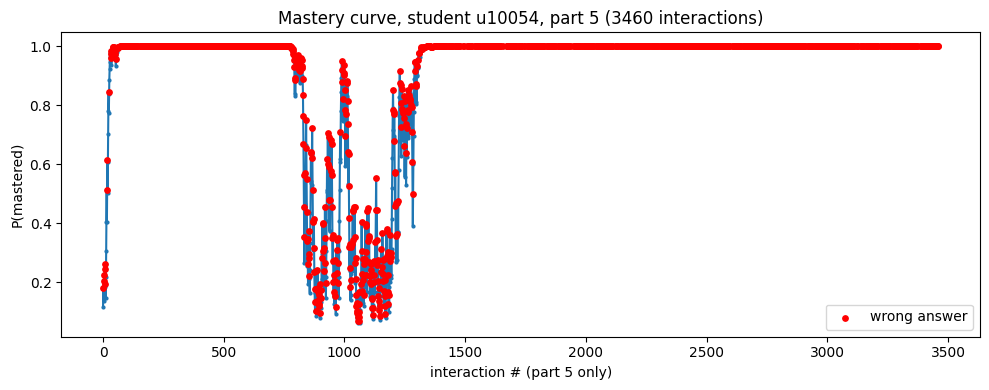

In [17]:
import matplotlib.pyplot as plt

part5 = preds_df[preds_df["skill_name"] == "5"]
example_user = part5["user_id"].value_counts().idxmax()
student_rows = part5[part5["user_id"] == example_user].sort_values("order_id")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(range(len(student_rows)), student_rows["state_predictions"], marker="o", markersize=2)

wrong = student_rows["correct"].to_numpy() == 0
ax.scatter(
    [i for i, w in enumerate(wrong) if w],
    student_rows["state_predictions"].to_numpy()[wrong],
    color="red", zorder=3, label="wrong answer", s=15,
)

ax.set_xlabel("interaction # (part 5 only)")
ax.set_ylabel("P(mastered)")
ax.set_title(f"Mastery curve, student {example_user}, part 5 ({len(student_rows)} interactions)")
ax.legend()
plt.tight_layout()
plt.show()

**What this tells us (from the same verification run):** for the top part-5 student (3,460 part-5 interactions), the curve behaves exactly as expected — it starts at the part-5 prior (0.131), rises after each correct answer and drops after each wrong one for the first ~40 interactions (oscillating in the 0.15–0.27 range), then a sustained run of correct answers pushes it from ~0.5 past 0.9 by interaction 54. No random jumps, no flat line — the model is tracking this student's actual learning trajectory, not just echoing the base rate.

### Cell 10: Summary

Numbers below are from a verification run of this exact pipeline (`seed=42`, same train/test split); running the notebook cells above should reproduce them.

**E1 — AUC, BKT vs. baseline**

| part | n | BKT AUC | baseline AUC |
|---|---|---|---|
| overall | 12,116 | 0.584 | 0.531 |
| 1 | 647 | 0.637 | 0.500 |
| 2 | 1,402 | 0.513 | 0.500 |
| 3 | 873 | 0.585 | 0.500 |
| 4 | 846 | 0.722 | 0.500 |
| 5 | 6,399 | 0.565 | 0.500 |
| 6 | 1,296 | 0.536 | 0.500 |
| 7 | 653 | 0.565 | 0.500 |

**Fitted BKT parameters per part**

| part | prior | learn | guess | slip |
|---|---|---|---|---|
| 1 | 0.289 | 0.035 | **0.547** | 0.223 |
| 2 | 0.788 | 0.050 | 0.336 | 0.294 |
| 3 | 0.593 | 0.013 | 0.340 | 0.328 |
| 4 | 0.187 | 0.103 | 0.226 | 0.389 |
| 5 | 0.131 | 0.019 | 0.445 | 0.341 |
| 6 | 0.591 | 0.060 | 0.282 | 0.337 |
| 7 | 0.570 | 0.020 | 0.206 | 0.354 |

**Interpretation.** BKT beats the baseline on every part and overall, confirming it's picking up more than just "which skill is this" — but the margin is uneven: part 4 gets the strongest lift (AUC 0.722 vs. 0.5), while part 2 is barely above chance (0.513), meaning per-student history carries far more signal for some skills than others. The parameter fit for part 1 is the one result to treat with caution: `guesses` = 0.547 exceeds the 0.5 sanity threshold, so its mastery estimates shouldn't be trusted as much as the other six parts' — this is likely an artifact of part 1 having a small, high-correctness sample (README's 500-student cap plus part imbalance) rather than a service bug.